# WLASL-100 feature engineering (v2 wrist-motion correction)

This notebook builds auditable temporal and fixed-length landmark features for the frozen signer-independent WLASL-100 split. It does not train or select models. Only corrected, valid landmark files enter the feature dataset; missing acquisitions remain visible.

## 1. Project context and input data

The inputs are 457 available sequences from 2,038 metadata instances—not a fully acquired WLASL-100 dataset. The landmark NPZ schema is inspected and validated before use, including the subject-anatomical handedness correction.

In [55]:
from pathlib import Path
import ast, json, os, tempfile, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

PROJECT_DIR=None
DEBUG_MODE=False; DEBUG_MAX_INSTANCES=10; FORCE_RECOMPUTE=True
TARGET_FRAMES=32
CORRECTION_STATUS='subject_anatomical_left_right__swapped_from_raw_mediapipe_selfie_labels_v1'
FEATURE_VERSION='wlasl100_landmark_features_v2'

def find_root(override=None):
    candidates=([Path(override).expanduser()] if override else [])+[Path.home()/'sign-language-recognition']
    here=Path.cwd().resolve(); candidates += [here,*here.parents]
    for p in candidates:
        if (p.resolve()/'WLASL/start_kit/WLASL_v0.3.json').is_file(): return p.resolve()
    raise FileNotFoundError('Set PROJECT_DIR to the project root.')
ROOT=find_root(PROJECT_DIR); DATA=ROOT/'data/processed/WLASL100'; LAND=DATA/'landmarks'; FEATURES=DATA/'features'/'v2'
TEMPORAL=FEATURES/'temporal'; CLASSICAL=FEATURES/'classical'; TRANSFORMERS=FEATURES/'transformers'; MANIFESTS=FEATURES/'manifests'; REPORTS=FEATURES/'reports'
for p in (TEMPORAL,CLASSICAL,TRANSFORMERS,MANIFESTS,REPORTS): p.mkdir(parents=True,exist_ok=True)
LANDMARK_MANIFEST=LAND/'landmark_manifest.csv'; ERROR_PATH=MANIFESTS/'feature_extraction_errors.csv'; FEATURE_MANIFEST=MANIFESTS/'feature_manifest.csv'
print(f'Project root: {ROOT}\nLandmarks: {LAND}\nFeatures: {FEATURES}')

Project root: /Users/sahilchauhan/sign-language-recognition
Landmarks: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/landmarks
Features: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/features/v2


## 2. Inspect landmark schema and validate corrected handedness

Expected arrays are Pose `(32,33,4)`, each hand `(32,21,3)`, and per-frame masks. Every accepted file must carry the explicit correction status written by the handedness audit; invalid files are recorded as exclusions rather than silently dropped.

In [56]:
manifest=pd.read_csv(LANDMARK_MANIFEST,dtype={'video_id':str,'signer_id':str})
success=manifest.loc[manifest.status.isin(['processed','skipped_existing_valid'])].copy().sort_values('video_id',kind='stable')
if success.empty: raise RuntimeError('No successful landmark rows found')
with np.load(success.iloc[0].landmark_path,allow_pickle=False) as z:
    schema={k:{'shape':list(z[k].shape),'dtype':str(z[k].dtype)} for k in z.files}
print(f'Landmark sequences listed as successful: {len(success)}'); print(json.dumps(schema,indent=2))

def scalar(z,key): return str(z[key].item())
def validate_landmark(path,row):
    with np.load(path,allow_pickle=False) as z:
        required={'pose','left_hand','right_hand','pose_detected','left_hand_detected','right_hand_detected','left_handedness_score','right_handedness_score','video_id','gloss','signer_id','experimental_split','handedness_correction_status'}
        missing=required-set(z.files)
        if missing: raise ValueError(f'missing keys {sorted(missing)}')
        if scalar(z,'handedness_correction_status') != CORRECTION_STATUS: raise ValueError('missing or unexpected handedness correction status')
        if scalar(z,'video_id')!=str(row.video_id) or scalar(z,'gloss')!=str(row.gloss) or scalar(z,'signer_id')!=str(row.signer_id) or scalar(z,'experimental_split')!=str(row.experimental_split): raise ValueError('NPZ metadata mismatch')
        if z['pose'].shape!=(32,33,4) or z['left_hand'].shape!=(32,21,3) or z['right_hand'].shape!=(32,21,3): raise ValueError('unexpected landmark dimensions')
        if any(np.isinf(z[k]).any() for k in ('pose','left_hand','right_hand')): raise ValueError('infinite coordinate')
    return True

Landmark sequences listed as successful: 1023
{
  "pose": {
    "shape": [
      32,
      33,
      4
    ],
    "dtype": "float32"
  },
  "left_hand": {
    "shape": [
      32,
      21,
      3
    ],
    "dtype": "float32"
  },
  "right_hand": {
    "shape": [
      32,
      21,
      3
    ],
    "dtype": "float32"
  },
  "pose_detected": {
    "shape": [
      32
    ],
    "dtype": "bool"
  },
  "left_hand_detected": {
    "shape": [
      32
    ],
    "dtype": "bool"
  },
  "right_hand_detected": {
    "shape": [
      32
    ],
    "dtype": "bool"
  },
  "left_handedness_score": {
    "shape": [
      32
    ],
    "dtype": "float32"
  },
  "right_handedness_score": {
    "shape": [
      32
    ],
    "dtype": "float32"
  },
  "video_id": {
    "shape": [],
    "dtype": "<U5"
  },
  "gloss": {
    "shape": [],
    "dtype": "<U8"
  },
  "signer_id": {
    "shape": [],
    "dtype": "<U1"
  },
  "experimental_split": {
    "shape": [],
    "dtype": "<U5"
  },
  "frame_count":

## 3. Load frozen metadata and split assignments

The frozen CSVs are validation sources only. The signer sets must remain disjoint, and every accepted landmark row must exactly match its frozen video, gloss, signer, and experimental split.

In [57]:
def frozen_metadata():
    pieces=[]
    for split in ('train','val','test'):
        df=pd.read_csv(DATA/f'{split}_metadata.csv',dtype={'video_id':str,'signer_id':str})
        df['video_id']=df.video_id.str.strip(); df['signer_id']=df.signer_id.astype(str).str.strip(); df['experimental_split']=split; pieces.append(df)
    out=pd.concat(pieces,ignore_index=True)
    if out.video_id.duplicated().any(): raise ValueError('Duplicate frozen video ID')
    sets={s:set(out.loc[out.experimental_split.eq(s),'signer_id']) for s in ('train','val','test')}
    if any(sets[a]&sets[b] for a in sets for b in sets if a<b): raise ValueError('Signer leakage in frozen splits')
    return out,sets
frozen,signer_sets=frozen_metadata()
joined=success.merge(frozen[['video_id','gloss','signer_id','experimental_split']],on='video_id',how='left',suffixes=('','_frozen'),validate='one_to_one')
for c in ('gloss','signer_id','experimental_split'):
    if joined[f'{c}_frozen'].isna().any() or not (joined[c].astype(str)==joined[f'{c}_frozen'].astype(str)).all(): raise ValueError(f'Frozen mismatch: {c}')
print({s:len(v) for s,v in signer_sets.items()}); display(success.groupby('experimental_split').size().rename('available_sequences').to_frame())

{'train': 62, 'val': 15, 'test': 20}


,available_sequences
experimental_split,
test,317
train,535
val,171


## 4. Feature engineering design

Temporal files preserve raw coordinates, body/wrist-relative coordinates, valid-consecutive velocity and acceleration, hand-to-body wrist positions, masks, and confidence. Missing coordinates remain `NaN`; derivative values are `NaN` unless both adjacent observations exist. Crucially, wrist motion is computed from `hand_to_body`, while wrist-relative hand coordinates are used only for hand configuration/shape.

In [58]:
POSE_XYZ=33*3; HAND_XYZ=21*3
def xyzw_to_xyz(pose): return pose[...,:3]
def shoulder_center(pose):
    shoulders=pose[:,[11,12],:3]
    return np.nanmean(shoulders,axis=1)
def relative_to(points,reference): return points-reference[:,None,:]
def valid_diff(values):
    out=np.full_like(values,np.nan,dtype=np.float32)
    valid=np.isfinite(values[1:]) & np.isfinite(values[:-1])
    out[1:]=np.where(valid,values[1:]-values[:-1],np.nan)
    return out
def safe_stats(x,prefix,names):
    finite=x[np.isfinite(x)]
    if not len(finite): vals=[np.nan]*4
    else: vals=[np.mean(finite),np.std(finite),np.min(finite),np.max(finite)]
    return vals,[f'{prefix}_{s}' for s in ('mean','std','min','max')]
def norm(v): return np.linalg.norm(v,axis=-1)

def temporal_payload(z):
    pose=xyzw_to_xyz(z['pose']).astype(np.float32); left=z['left_hand'].astype(np.float32); right=z['right_hand'].astype(np.float32)
    body=shoulder_center(pose); pose_rel=relative_to(pose,body)
    left_rel=relative_to(left,left[:,0,:]); right_rel=relative_to(right,right[:,0,:])
    raw=np.concatenate([pose.reshape(32,-1),left.reshape(32,-1),right.reshape(32,-1)],axis=1)
    relative=np.concatenate([pose_rel.reshape(32,-1),left_rel.reshape(32,-1),right_rel.reshape(32,-1)],axis=1)
    hand_body=np.concatenate([left[:,0,:]-body,right[:,0,:]-body],axis=1)
    hand_body_velocity = valid_diff(hand_body).astype(np.float32)
    hand_body_acceleration = valid_diff(hand_body_velocity).astype(np.float32)
    velocity=valid_diff(relative); acceleration=valid_diff(velocity)
    masks=np.column_stack([z['pose_detected'],z['left_hand_detected'],z['right_hand_detected'],np.isfinite(z['left_handedness_score']),np.isfinite(z['right_handedness_score'])]).astype(np.uint8)
    confidence=np.column_stack([z['left_handedness_score'],z['right_handedness_score']]).astype(np.float32)

    assert hand_body.shape == (32, 6)
    assert hand_body_velocity.shape == (32, 6)
    assert hand_body_acceleration.shape == (32, 6)
    assert np.isnan(hand_body_velocity[0]).all()
    assert np.isnan(hand_body_acceleration[:2]).all()
    return {
    'raw_coordinates': raw,
    'relative_coordinates': relative,
    'hand_to_body': hand_body.astype(np.float32),
    'velocity': velocity,
    'acceleration': acceleration,
    'hand_body_velocity': hand_body_velocity,
    'hand_body_acceleration': hand_body_acceleration,
    'detection_masks': masks,
    'hand_confidence': confidence,
    'coordinate_missing_mask': (~np.isfinite(raw)).astype(np.uint8)
}

def classical_vector(t):
    values=[]; names=[]
    masks=t['detection_masks']; conf=t['hand_confidence']; rel=t['relative_coordinates']; handbody=t['hand_to_body']; vel=t['velocity']; acc=t['acceleration']
    for i,label in enumerate(['pose','left_hand','right_hand']): values.append(float(masks[:,i].mean())); names.append(f'detection_{label}_ratio')
    for i,label in enumerate(['left','right']):
        values.append(float(np.nanmean(conf[:,i]))); names.append(f'{label}_handedness_confidence_mean')
    # Wrist relative to shoulder centre: never use wrist-relative hand coordinate (which is zero by construction).
    for side,wrist in [('left',handbody[:,:3]),('right',handbody[:,3:6])]:
        speed=norm(valid_diff(wrist)); accel=norm(valid_diff(valid_diff(wrist)))
        for arr,label in [(speed,'wrist_speed'),(accel,'wrist_acceleration'),(norm(wrist),'wrist_body_distance')]:
            v,n=safe_stats(arr,f'{side}_{label}',names); values+=v; names+=n
        displacement=norm(wrist[-1]-wrist[0]) if np.isfinite(wrist[[0,-1]]).all() else np.nan
        values.append(displacement); names.append(f'{side}_wrist_start_end_displacement')
    # Shoulder width and inter-wrist geometry in relative space.
    pose=rel[:,:POSE_XYZ].reshape(32,33,3); lw_body=handbody[:,:3]; rw_body=handbody[:,3:6]
    for arr,label in [(norm(pose[:,11]-pose[:,12]),'shoulder_width'),(norm(lw_body-rw_body),'inter_wrist_distance')]:
        v,n=safe_stats(arr,label,names); values+=v; names+=n
    # Five fingertip-to-wrist distances per hand: compact hand-shape signal.
    for side,base in [('left',POSE_XYZ),('right',POSE_XYZ+HAND_XYZ)]:
        hand=rel[:,base:base+HAND_XYZ].reshape(32,21,3)
        for tip in (4,8,12,16,20):
            v,n=safe_stats(norm(hand[:,tip]),f'{side}_tip{tip}_to_wrist',names); values+=v[:2]; names+=n[:2]
    # Selected relative trajectories: pose nose and both wrists, x/y/z mean/std/range.
    for label,arr in [('nose',pose[:,0]),('left_wrist',lw_body),('right_wrist',rw_body)]:
        for axis,name in enumerate('xyz'):
            finite=arr[:,axis][np.isfinite(arr[:,axis])]
            vals=[np.nan,np.nan,np.nan] if not len(finite) else [finite.mean(),finite.std(),finite.max()-finite.min()]
            values+=vals; names += [f'{label}_{name}_{s}' for s in ('mean','std','range')]
    return np.asarray(values,np.float32),names

## 5. Missing-data representation and train-only preprocessing

Temporal files retain `NaN` plus masks; no interpolation is performed. Classical features may have `NaN` when a signal is absent. Median imputation with missingness indicators and standard scaling are fitted **only on training rows**, then applied unchanged to validation and test rows. The fitted objects are saved for later model notebooks.

In [59]:
CONFIG={'feature_version':FEATURE_VERSION,'temporal_steps':32,'coordinate_order':'pose_xyz, left_hand_xyz, right_hand_xyz','temporal_arrays': [
    'raw_coordinates',
    'relative_coordinates',
    'hand_to_body',
    'velocity',
    'acceleration',
    'hand_body_velocity',
    'hand_body_acceleration',
    'detection_masks',
    'hand_confidence',
    'coordinate_missing_mask'
],'missing_data':'temporal NaN plus explicit masks; classical train-only median imputation with indicators','derivative_convention':'first frame and invalid-consecutive differences are NaN','handedness_required_status':CORRECTION_STATUS}
(FEATURES/'feature_config.json').write_text(json.dumps(CONFIG,indent=2))

718

## 6. Generate temporal and classical datasets

Files are processed one at a time and atomically written. A malformed or uncorrected input becomes an audit row and does not enter the final arrays. Existing feature files are reusable unless force recomputation is requested.

In [60]:
work=success.head(DEBUG_MAX_INSTANCES).copy() if DEBUG_MODE else success.copy()
records=[]; errors=[]; feature_names=None
for row in tqdm(work.itertuples(index=False),total=len(work),desc='Engineering features'):
    temporal_path=TEMPORAL/f'{row.video_id}.npz'; classical_path=CLASSICAL/f'{row.video_id}.npz'
    base={'video_id':row.video_id,'gloss':row.gloss,'signer_id':str(row.signer_id),'experimental_split':row.experimental_split,'source_landmark_path':row.landmark_path,'temporal_path':str(temporal_path),'classical_path':str(classical_path)}
    try:
        validate_landmark(row.landmark_path,row)
        with np.load(row.landmark_path,allow_pickle=False) as z: data={k:z[k] for k in z.files}
        t=temporal_payload(data); vector,names=classical_vector(t)
        if feature_names is None: feature_names=names
        elif feature_names!=names: raise RuntimeError('Feature name/order drift')
        def atomic(path,payload):
            with tempfile.NamedTemporaryFile(dir=path.parent,suffix='.npz',delete=False) as h: temp=Path(h.name)
            try: np.savez_compressed(temp,**payload); os.replace(temp,path)
            finally:
                if temp.exists(): temp.unlink()
        if FORCE_RECOMPUTE or not temporal_path.exists(): atomic(temporal_path,t|{'video_id':np.array(row.video_id),'feature_version':np.array(FEATURE_VERSION)})
        if FORCE_RECOMPUTE or not classical_path.exists(): atomic(classical_path,{'features':vector,'video_id':np.array(row.video_id),'feature_version':np.array(FEATURE_VERSION)})
        records.append(base|{'status':'processed','error_reason':'','temporal_shape':str(t['relative_coordinates'].shape),'classical_feature_count':len(vector),'classical_missing_values':int(np.isnan(vector).sum()),'low_detection_quality':bool(row.low_detection_quality)})
    except Exception as e:
        msg=f'{type(e).__name__}: {e}'; records.append(base|{'status':'excluded','error_reason':msg,'temporal_shape':'','classical_feature_count':0,'classical_missing_values':0,'low_detection_quality':False}); errors.append(base|{'error_type':type(e).__name__,'error_message':str(e)})
feature_manifest=pd.DataFrame(records); feature_manifest.to_csv(FEATURE_MANIFEST,index=False)
pd.DataFrame(errors,columns=['video_id','gloss','signer_id','experimental_split','source_landmark_path','temporal_path','classical_path','error_type','error_message']).to_csv(ERROR_PATH,index=False)
if feature_names is None: raise RuntimeError('No valid features were generated')
(FEATURES/'feature_names.json').write_text(json.dumps({'feature_names':feature_names,'count':len(feature_names)},indent=2))
print(f'Processed: {(feature_manifest.status=="processed").sum()}; excluded: {(feature_manifest.status=="excluded").sum()}; classical features: {len(feature_names)}')

Engineering features:   0%|          | 0/1023 [00:00<?, ?it/s]/var/folders/sv/qsh8nfp908z0x4hjly1q7tw40000gn/T/ipykernel_14182/1521182816.py:55: RuntimeWarning: Mean of empty slice
  values.append(float(np.nanmean(conf[:,i]))); names.append(f'{label}_handedness_confidence_mean')
/var/folders/sv/qsh8nfp908z0x4hjly1q7tw40000gn/T/ipykernel_14182/1521182816.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(shoulders,axis=1)
Engineering features: 100%|██████████| 1023/1023 [00:04<00:00, 220.34it/s]

Processed: 1023; excluded: 0; classical features: 86


## 7. Classical train-only preprocessing and saved split datasets

Raw vectors are preserved per instance. The train-fitted imputer/scaler create companion split matrices for classical models. Labels remain gloss strings; this notebook does not fit a label encoder or train a classifier.

In [61]:
usable=feature_manifest.loc[feature_manifest.status.eq('processed')].copy()
def load_vector(path):
    with np.load(path,allow_pickle=False) as z: return z['features']
matrices={s:np.stack([load_vector(p) for p in usable.loc[usable.experimental_split.eq(s),'classical_path']]) for s in ('train','val','test')}
if len(matrices['train'])==0: raise RuntimeError('No train features for fitting')
imputer=SimpleImputer(strategy='median',add_indicator=True); scaler=StandardScaler()
X_train=scaler.fit_transform(imputer.fit_transform(matrices['train']))
joblib.dump(imputer,TRANSFORMERS/'classical_imputer_train_only.joblib'); joblib.dump(scaler,TRANSFORMERS/'classical_scaler_train_only.joblib')
for split,Xraw in matrices.items():
    Xscaled=X_train if split=='train' else scaler.transform(imputer.transform(Xraw))
    rows=usable.loc[usable.experimental_split.eq(split)]
    np.savez_compressed(CLASSICAL/f'{split}_dataset.npz',X_raw=Xraw,X_imputed_scaled=Xscaled.astype(np.float32),video_id=rows.video_id.to_numpy(),gloss=rows.gloss.to_numpy(),signer_id=rows.signer_id.to_numpy(),feature_names=np.array(feature_names))
print({s:matrices[s].shape for s in matrices},'scaled dimension:',X_train.shape[1])

{'train': (535, 86), 'val': (171, 86), 'test': (317, 86)} scaled dimension: 156


## 8. Quality checks, wrist-motion diagnostics, and visualizations

Checks ensure 32 time steps, matching output identities, finite scaled matrices, preserved signer splits, and train-only fitted objects. Plots illustrate representations and missingness without using labels for feature selection.

PASS: Signer-independent splits verified.
PASS: Validated 1023 temporal and classical feature files.
PASS: All temporal arrays have expected shapes and dtypes.
PASS: Train-only imputed classical features are finite.


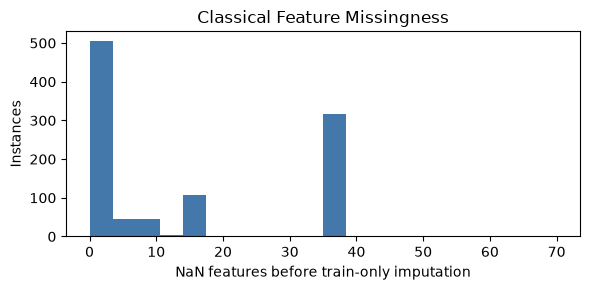

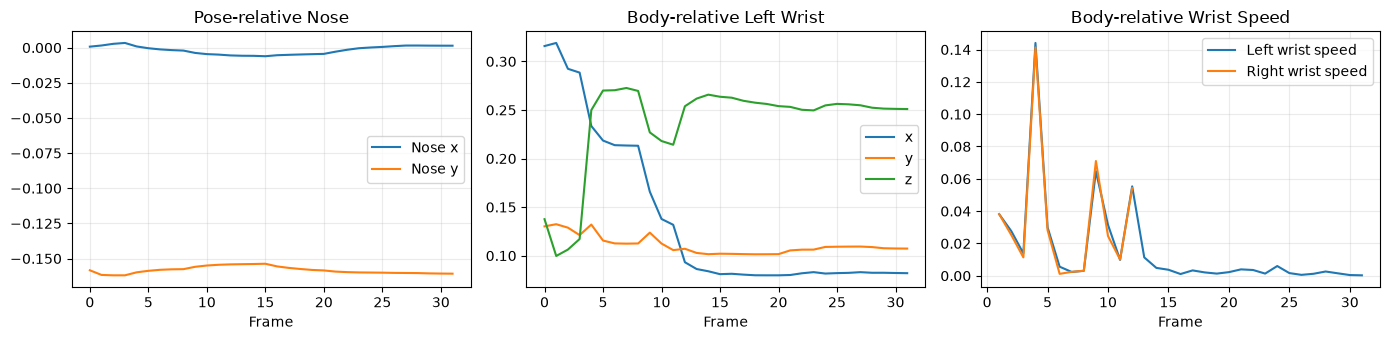

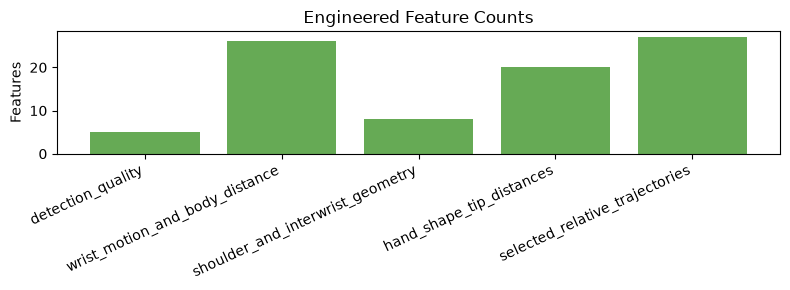

,video_id,split,side,v1_wrist_relative_speed_mean,v2_body_relative_speed_mean,v2_start_end_displacement
0,00618,train,left,0.0,0.015456,0.260937
1,00618,train,right,0.0,0.034257,NaN
2,09847,train,left,0.0,0.007808,0.010906
3,09847,train,right,0.0,0.008230,0.010530
4,17016,train,left,0.0,0.034813,NaN
5,17016,train,right,0.0,0.016963,NaN
6,28110,val,left,NaN,NaN,NaN
7,28110,val,right,0.0,0.026473,NaN
8,39003,test,left,0.0,0.089622,NaN
9,39003,test,right,0.0,0.034393,NaN



FEATURE ENGINEERING VALIDATION COMPLETE
Total usable instances: 1023
Temporal arrays per instance: 10
Classical raw features: 86
Classical transformed features: 156

All validation checks passed.
Signer independence: VERIFIED
Temporal feature integrity: VERIFIED
Body-relative wrist motion: VERIFIED
Classical feature integrity: VERIFIED
Train feature finiteness: VERIFIED


In [62]:
# ============================================================
# FINAL VALIDATION: FEATURE ENGINEERING
# ============================================================

# 1. Verify signer-independent splits
assert not (
    signer_sets['train'] & signer_sets['val']
    or signer_sets['train'] & signer_sets['test']
    or signer_sets['val'] & signer_sets['test']
), "Signer overlap detected between splits!"

print("PASS: Signer-independent splits verified.")


# 2. Validate all temporal and classical feature files
temporal_keys = [
    'raw_coordinates',
    'relative_coordinates',
    'hand_to_body',
    'velocity',
    'acceleration',
    'hand_body_velocity',
    'hand_body_acceleration',
    'detection_masks',
    'hand_confidence',
    'coordinate_missing_mask'
]

for row in usable.itertuples(index=False):

    # Temporal features
    with np.load(row.temporal_path, allow_pickle=False) as z:

        # Ensure all expected arrays exist
        assert all(key in z.files for key in temporal_keys), (
            f"Missing temporal arrays: {row.video_id}"
        )

        assert z['raw_coordinates'].shape == (32, 225)
        assert z['relative_coordinates'].shape == (32, 225)
        assert z['velocity'].shape == (32, 225)
        assert z['acceleration'].shape == (32, 225)
        assert z['coordinate_missing_mask'].shape == (32, 225)

        assert z['detection_masks'].shape == (32, 5)
        assert z['hand_confidence'].shape == (32, 2)

        # Body-relative wrist features
        for key in (
            'hand_to_body',
            'hand_body_velocity',
            'hand_body_acceleration'
        ):
            assert z[key].shape == (32, 6), (
                f"{key} has incorrect shape: {row.video_id}"
            )
            assert z[key].dtype == np.float32, (
                f"{key} has incorrect dtype: {row.video_id}"
            )

        # Derivative initialization conventions
        assert np.isnan(z['hand_body_velocity'][0]).all()
        assert np.isnan(z['hand_body_acceleration'][:2]).all()

    # Classical features
    with np.load(row.classical_path, allow_pickle=False) as z:
        assert z['features'].shape == (len(feature_names),)


assert np.isfinite(X_train).all(), (
    "Non-finite values found in training classical features!"
)

print(f"PASS: Validated {len(usable)} temporal and classical feature files.")
print("PASS: All temporal arrays have expected shapes and dtypes.")
print("PASS: Train-only imputed classical features are finite.")


# 3. Classical feature missingness distribution
missing = usable.classical_missing_values

plt.figure(figsize=(6, 3))
plt.hist(missing, bins=20, color='#4477AA')
plt.xlabel('NaN features before train-only imputation')
plt.ylabel('Instances')
plt.title('Classical Feature Missingness')
plt.tight_layout()
plt.savefig(REPORTS / 'classical_missingness.png', dpi=150)
plt.show()


# 4. Visualize an example temporal feature sequence
example = usable.iloc[0]

with np.load(example.temporal_path, allow_pickle=False) as z:
    relative = z['relative_coordinates']
    velocity = z['velocity']
    handbody = z['hand_to_body']
    handbody_velocity = z['hand_body_velocity']
    masks = z['detection_masks']

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

# Pose-relative nose coordinates
axes[0].plot(relative[:, 0], label='Nose x')
axes[0].plot(relative[:, 1], label='Nose y')
axes[0].set_title('Pose-relative Nose')
axes[0].legend()

# Body-relative left wrist trajectory
axes[1].plot(handbody[:, 0], label='x')
axes[1].plot(handbody[:, 1], label='y')
axes[1].plot(handbody[:, 2], label='z')
axes[1].set_title('Body-relative Left Wrist')
axes[1].legend()

# Saved body-relative wrist velocity
axes[2].plot(
    norm(handbody_velocity[:, :3]),
    label='Left wrist speed'
)
axes[2].plot(
    norm(handbody_velocity[:, 3:6]),
    label='Right wrist speed'
)
axes[2].set_title('Body-relative Wrist Speed')
axes[2].legend()

for ax in axes:
    ax.set_xlabel('Frame')
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(REPORTS / 'temporal_feature_example.png', dpi=150)
plt.show()


# 5. Feature group distribution
group_counts = {
    'detection_quality': 5,
    'wrist_motion_and_body_distance': 26,
    'shoulder_and_interwrist_geometry': 8,
    'hand_shape_tip_distances': 20,
    'selected_relative_trajectories': 27
}

assert sum(group_counts.values()) == len(feature_names) == 86

plt.figure(figsize=(8, 3))
plt.bar(
    group_counts.keys(),
    group_counts.values(),
    color='#66AA55'
)
plt.xticks(rotation=25, ha='right')
plt.ylabel('Features')
plt.title('Engineered Feature Counts')
plt.tight_layout()
plt.savefig(REPORTS / 'feature_group_counts.png', dpi=150)
plt.show()


# 6. Diagnose v1 wrist-relative bug versus corrected v2 motion
diagnostic = []

for row in usable.sort_values('video_id').iloc[
    np.linspace(
        0,
        len(usable) - 1,
        min(8, len(usable)),
        dtype=int
    )
].itertuples(index=False):

    with np.load(row.temporal_path, allow_pickle=False) as z:

        rel = z['relative_coordinates']
        body = z['hand_to_body']
        body_velocity = z['hand_body_velocity']

        for side, legacy, corrected, corrected_velocity in [
            (
                'left',
                rel[:, 99:102],
                body[:, :3],
                body_velocity[:, :3]
            ),
            (
                'right',
                rel[:, 162:165],
                body[:, 3:6],
                body_velocity[:, 3:6]
            )
        ]:

            legacy_speed = norm(valid_diff(legacy))
            corrected_speed = norm(corrected_velocity)

            endpoint = (
                norm(corrected[-1] - corrected[0])
                if np.isfinite(corrected[[0, -1]]).all()
                else np.nan
            )

            diagnostic.append({
                'video_id': row.video_id,
                'split': row.experimental_split,
                'side': side,
                'v1_wrist_relative_speed_mean': (
                    float(np.nanmean(legacy_speed))
                    if np.isfinite(legacy_speed).any()
                    else np.nan
                ),
                'v2_body_relative_speed_mean': (
                    float(np.nanmean(corrected_speed))
                    if np.isfinite(corrected_speed).any()
                    else np.nan
                ),
                'v2_start_end_displacement': float(endpoint)
            })

diagnostic = pd.DataFrame(diagnostic)

diagnostic.to_csv(
    REPORTS / 'wrist_motion_v1_vs_v2_diagnostic.csv',
    index=False
)

display(diagnostic)


# 7. Structural validation of wrist coordinate representations
zero_checks = []
nonzero_body = False

for row in usable.itertuples(index=False):

    with np.load(row.temporal_path, allow_pickle=False) as z:

        rel = z['relative_coordinates']
        body = z['hand_to_body']

        for local, global_ in [
            (rel[:, 99:102], body[:, :3]),
            (rel[:, 162:165], body[:, 3:6])
        ]:

            finite = local[np.isfinite(local)]

            if finite.size:
                zero_checks.append(np.max(np.abs(finite)))

            if (
                np.isfinite(global_).any()
                and np.nanmax(np.abs(global_)) > 1e-6
            ):
                nonzero_body = True


assert all(
    value < 1e-6 for value in zero_checks
), "Wrist-relative hand coordinates should be zero at landmark 0."

assert nonzero_body, (
    "Body-relative wrist trajectories were unexpectedly forced to zero."
)

assert (
    diagnostic['v2_body_relative_speed_mean'].notna().any()
    and np.isfinite(
        diagnostic['v2_body_relative_speed_mean'].dropna()
    ).all()
), "Invalid v2 wrist-motion diagnostic."


# 8. Final completion summary
print("\n" + "=" * 55)
print("FEATURE ENGINEERING VALIDATION COMPLETE")
print("=" * 55)

print(f"Total usable instances: {len(usable)}")
print(f"Temporal arrays per instance: {len(temporal_keys)}")
print(f"Classical raw features: {len(feature_names)}")
print(f"Classical transformed features: {X_train.shape[1]}")

print("\nAll validation checks passed.")
print("Signer independence: VERIFIED")
print("Temporal feature integrity: VERIFIED")
print("Body-relative wrist motion: VERIFIED")
print("Classical feature integrity: VERIFIED")
print("Train feature finiteness: VERIFIED")
print("=" * 55)

10## 9. Save summary and next steps

Notebook 06 can use the saved classical split datasets and train-only transformers. Notebook 07 can consume per-instance temporal files while retaining masks and `NaN` semantics. Known limitations: only 1023 instances are available, validation coverage is sparse, and no model experiment has yet established which representation performs best.

In [63]:
summary={'feature_version':FEATURE_VERSION,'landmark_sequences_inspected':int(len(work)),'successfully_processed':int(len(usable)),'excluded':int((feature_manifest.status=='excluded').sum()),'excluded_reasons':pd.Series(errors and [e['error_type'] for e in errors] or [],dtype=str).value_counts().to_dict(),'temporal_relative_shape_per_instance':[32,225],'temporal_arrays':CONFIG['temporal_arrays'],'classical_raw_feature_count':len(feature_names),'classical_scaled_feature_count':int(X_train.shape[1]),'feature_group_counts':group_counts,'missing_strategy':CONFIG['missing_data'],'train_only_transformers':['classical_imputer_train_only.joblib','classical_scaler_train_only.joblib'],'split_counts':usable.experimental_split.value_counts().to_dict(),'signer_independence_preserved':True,'handedness_status_required':CORRECTION_STATUS}
(FEATURES/'feature_extraction_summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2)); print(f'Outputs: {FEATURES}')

{
  "feature_version": "wlasl100_landmark_features_v2",
  "landmark_sequences_inspected": 1023,
  "successfully_processed": 1023,
  "excluded": 0,
  "excluded_reasons": {},
  "temporal_relative_shape_per_instance": [
    32,
    225
  ],
  "temporal_arrays": [
    "raw_coordinates",
    "relative_coordinates",
    "hand_to_body",
    "velocity",
    "acceleration",
    "hand_body_velocity",
    "hand_body_acceleration",
    "detection_masks",
    "hand_confidence",
    "coordinate_missing_mask"
  ],
  "classical_raw_feature_count": 86,
  "classical_scaled_feature_count": 156,
  "feature_group_counts": {
    "detection_quality": 5,
    "wrist_motion_and_body_distance": 26,
    "shoulder_and_interwrist_geometry": 8,
    "hand_shape_tip_distances": 20,
    "selected_relative_trajectories": 27
  },
  "missing_strategy": "temporal NaN plus explicit masks; classical train-only median imputation with indicators",
  "train_only_transformers": [
    "classical_imputer_train_only.joblib",
    "c